# LAB 07 - Transformer Architecture

Ghép self-attention của LAB 06 thành Transformer Encoder: Embedding → Positional Encoding → Multi-Head Self-Attention → Add & Norm → FFN → Add & Norm → Pooling → Classifier.

- `positional_encoding.py`: sinusoidal PE. `transformer_block.py`: Transformer block tự ghép (không dùng `nn.TransformerEncoderLayer`).
- Dữ liệu IMDb, cùng split với LAB 04 - 06, dùng lại `lab4/preprocessing.py`.
- Notebook ghi `results.csv` và các hình `.png`.

## 0. Setup

In [1]:
import math
import os
import sys
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import spearmanr
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score)

sys.path.insert(0, os.path.abspath("../lab4"))
from preprocessing import LABEL_NAMES, deduplicate, load_imdb, preprocess, remove_overlap, split_train_val
from positional_encoding import PositionalEncoding, sinusoidal_pe
from transformer_block import TransformerBlock

SEED = 42
QUICK = os.environ.get("LAB7_QUICK") == "1"     # chạy thử nhanh trên tập con
torch.set_num_threads(8)
pd.set_option("display.max_colwidth", 160)

MAX_VOCAB = 20000
D_MODEL = 128          # embedding dim cho cả LSTM và Transformer
N_HEADS = 4
D_FF = 256
N_LAYERS = 1
DROPOUT = 0.1          # trong Transformer block
HEAD_DROPOUT = 0.3     # trước classifier (giống LAB 05 - 06)
BATCH = 64
LR = 1e-3
EPOCHS = 2 if QUICK else 5
CLIP = 1.0
MAX_LEN = 128
PAD, UNK, CLS = 0, 1, 2

RESULTS = []
def log(experiment, model, setting, split, metric, value):
    RESULTS.append({"experiment": experiment, "model": model, "setting": setting,
                    "split": split, "metric": metric, "value": value})

def metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0), "f1": f1_score(y_true, y_pred, zero_division=0)}

def softmax_np(s):
    e = np.exp(s - s.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)

print("torch", torch.__version__, "| QUICK =", QUICK)

torch 2.13.0+cpu | QUICK = False


## 1. Kiểm tra bài tính (calculations.md)

In [2]:
X1 = np.array([[1, 0, 1, 0], [0, 1, 0, 1], [1, 1, 0, 0]], float)
WQ = np.array([[1, 0], [0, 1], [1, 0], [0, 1]], float)
WK = np.array([[1, 0], [0, 1], [0, 0], [0, 0]], float)
WV = np.array([[1, 0], [0, 0], [0, 1], [0, 1]], float)
Q1, K1, V1 = X1 @ WQ, X1 @ WK, X1 @ WV
A1 = softmax_np(Q1 @ K1.T / np.sqrt(2))
print("Bài 1: A =\n", A1.round(3), "\nZ = AV =\n", (A1 @ V1).round(3))
print("Multi-head: concat của 2 head (3×2) →", np.concatenate([A1 @ V1, A1 @ V1], axis=1).shape)
print("PE d = 4, pos = 0..2:\n", sinusoidal_pe(3, 4).round(3))
h = np.maximum(np.eye(2) @ np.array([1, 2]) + np.array([0, -1]), 0)
y = np.array([[1, 1], [1, -1]]) @ h + np.array([0, 0.5])
print("FFN: h =", h, " y =", y, " residual x + y =", np.array([1, 2]) + y)
blk = TransformerBlock(128, 4, 256)
blk(torch.randn(8, 100, 128))
print("Shape (B=8, T=100, d=128, h=4):", blk.shapes)
for k, v in blk.shapes.items():
    log("shapes", "TransformerBlock", "B=8,T=100,d=128,h=4", "-", k, str(v))

Bài 1: A =
 [[0.446 0.108 0.446]
 [0.108 0.446 0.446]
 [0.248 0.248 0.503]] 
Z = AV =
 [[0.892 0.554]
 [0.554 0.554]
 [0.752 0.497]]
Multi-head: concat của 2 head (3×2) → (3, 4)
PE d = 4, pos = 0..2:
 [[ 0.     1.     0.     1.   ]
 [ 0.841  0.54   0.01   1.   ]
 [ 0.909 -0.416  0.02   1.   ]]
FFN: h = [1. 1.]  y = [2.  0.5]  residual x + y = [3.  2.5]
Shape (B=8, T=100, d=128, h=4): {'x': (8, 100, 128), 'Q': (8, 4, 100, 32), 'K': (8, 4, 100, 32), 'V': (8, 4, 100, 32), 'scores': (8, 4, 100, 100), 'weights': (8, 4, 100, 100), 'heads': (8, 4, 100, 32), 'concat': (8, 100, 128), 'output': (8, 100, 128), 'ffn_hidden': (8, 100, 256), 'block_output': (8, 100, 128)}


## 2. Experiment 1 - Positional encoding

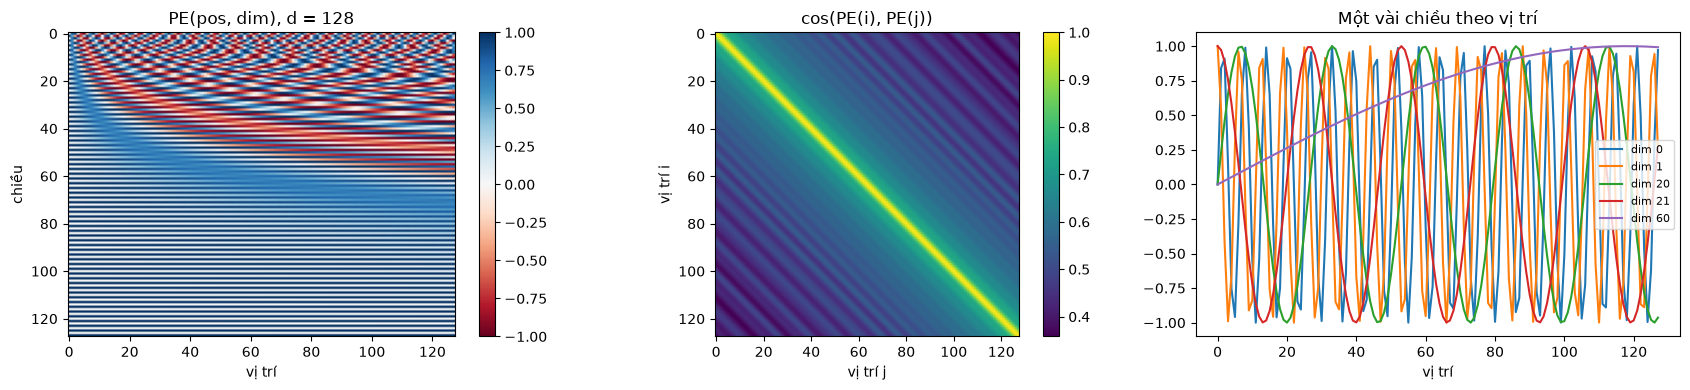

cos giữa vị trí 0 và 1, 5, 20, 100: [0.97, 0.737, 0.608, 0.477]


In [3]:
PE = sinusoidal_pe(128, 128)
unit = PE / np.linalg.norm(PE, axis=1, keepdims=True)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
im = axes[0].imshow(PE.T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
axes[0].set(title="PE(pos, dim), d = 128", xlabel="vị trí", ylabel="chiều")
plt.colorbar(im, ax=axes[0])
im = axes[1].imshow(unit @ unit.T, cmap="viridis")
axes[1].set(title="cos(PE(i), PE(j))", xlabel="vị trí j", ylabel="vị trí i")
plt.colorbar(im, ax=axes[1])
for d in [0, 1, 20, 21, 60]:
    axes[2].plot(PE[:, d], label=f"dim {d}")
axes[2].set(title="Một vài chiều theo vị trí", xlabel="vị trí")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig("positional_encoding.png", dpi=120)
plt.show()
print("cos giữa vị trí 0 và 1, 5, 20, 100:", [round(float(unit[0] @ unit[k]), 3) for k in [1, 5, 20, 100]])

### "I love NLP" và "NLP love I"

Embedding ngẫu nhiên (d = 8) và một Transformer block chưa train (2 head). So sánh output của từng token và vector mean pooling, không có và có PE.

In [4]:
torch.manual_seed(SEED)
toy_vocab = {w: i for i, w in enumerate(["I", "love", "NLP", "dog", "bites", "man"])}
toy_emb = nn.Embedding(len(toy_vocab), 8)
toy_blk = TransformerBlock(8, 2, 16, dropout=0.0).eval()
toy_pe = PositionalEncoding(8, max_len=16)

@torch.no_grad()
def encode_toy(words, use_pe):
    x = toy_emb(torch.tensor([[toy_vocab[w] for w in words]]))
    if use_pe:
        x = toy_pe(x)
    return toy_blk(x)[0][0]

def compare(s1, s2):
    w1, w2 = s1.split(), s2.split()
    rows = []
    for use_pe in [False, True]:
        H1, H2 = encode_toy(w1, use_pe), encode_toy(w2, use_pe)
        same_word = {w: (H1[w1.index(w)] - H2[w2.index(w)]).norm().item() for w in w1}
        rows.append({"PE": use_pe, "‖mean(H1) − mean(H2)‖": (H1.mean(0) - H2.mean(0)).norm().item(),
                     "cos(mean H1, mean H2)": F.cosine_similarity(H1.mean(0), H2.mean(0), dim=0).item(),
                     **{f"‖h({w}) S1 − h({w}) S2‖": v for w, v in same_word.items()}})
    return pd.DataFrame(rows).set_index("PE")

exp1 = compare("I love NLP", "NLP love I")
for pe_flag, r in exp1.iterrows():
    for k, v in r.items():
        log("exp1_positional", "random block", f"PE={pe_flag}", "-", k, v)
exp1.round(4)

,‖mean(H1) − mean(H2)‖,"cos(mean H1, mean H2)",‖h(I) S1 − h(I) S2‖,‖h(love) S1 − h(love) S2‖,‖h(NLP) S1 − h(NLP) S2‖
PE,,,,,
False,0.0000,1.0000,0.0000,0.0000,0.0000
True,0.1738,0.9982,1.0255,0.1149,1.3298


## 3. Permutation experiment: "dog bites man" vs "man bites dog"

A: self-attention không PE. B: self-attention + PE. Cùng embedding và block ở trên. Kết quả trên model đã train ở mục 5.

In [5]:
perm = compare("dog bites man", "man bites dog")
for pe_flag, r in perm.iterrows():
    for k, v in r.items():
        log("permutation", "random block", f"PE={pe_flag}", "-", k, v)
perm.round(4)

,‖mean(H1) − mean(H2)‖,"cos(mean H1, mean H2)",‖h(dog) S1 − h(dog) S2‖,‖h(bites) S1 − h(bites) S2‖,‖h(man) S1 − h(man) S2‖
PE,,,,,
False,0.0000,1.0000,0.0000,0.000,0.0000
True,0.2577,0.9892,1.6717,0.098,1.3592


**Không có PE:** "I love NLP" và "NLP love I" (cũng như "dog bites man" và "man bites dog") cho representation của từng từ **giống hệt nhau** (khoảng cách 0.000), chỉ đổi chỗ, nên mean pooling giống hệt (cos = 1.000). Self-attention, FFN và LayerNorm đều không phụ thuộc vị trí.

**Có PE:** cùng một từ ở vị trí khác nhau thì có vector khác nhau. "dog" ở đầu và ở cuối câu cách nhau 1.67, "man" 1.36. "bites" ở cùng vị trí giữa nên chỉ khác 0.10. Vector của cả câu cũng khác nhau.

**PE:** mỗi vị trí có một vector riêng. Vị trí gần nhau giống nhau hơn: cos(PE₀, PE₁) = 0.97, cos(PE₀, PE₂₀) = 0.61, cos(PE₀, PE₁₀₀) = 0.48.

## 4. Dữ liệu, model và training

In [6]:
train_raw, test_raw = load_imdb()
train_full = deduplicate(train_raw)
test_df = remove_overlap(deduplicate(test_raw), train_full)
train_df, val_df = split_train_val(train_full, val_size=0.2, seed=SEED)
if QUICK:
    train_df = train_df.sample(3000, random_state=SEED).reset_index(drop=True)
    val_df = val_df.sample(500, random_state=SEED).reset_index(drop=True)
    test_df = test_df.sample(1000, random_state=SEED).reset_index(drop=True)
y_train, y_val, y_test = train_df["label"].values, val_df["label"].values, test_df["label"].values
tok_train, tok_val, tok_test = ([preprocess(t) for t in d["text"]] for d in (train_df, val_df, test_df))

counter = Counter(w for toks in tok_train for w in toks)
itos = ["<pad>", "<unk>", "<cls>"] + [w for w, _ in counter.most_common(MAX_VOCAB)]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB_SIZE = len(itos)
encode = lambda toks: [stoi.get(w, UNK) for w in toks]
ids_train, ids_val, ids_test = ([encode(t) for t in toks] for toks in (tok_train, tok_val, tok_test))
len_test = np.array([len(x) for x in ids_test])
print("train / val / test:", len(train_df), len(val_df), len(test_df), "| vocab:", VOCAB_SIZE)

def to_tensors(ids_list, L, cls=False):
    rows, lens = [], []
    for ids in ids_list:
        ids = ([CLS] + ids[: L - 1]) if cls else ids[:L]
        n = max(len(ids), 1)
        rows.append(ids + [PAD] * (L - len(ids))); lens.append(n)
    return torch.tensor(rows), torch.tensor(lens)

train / val / test: 19923 4981 24678 | vocab: 20003


In [7]:
class TransformerClassifier(nn.Module):
    """Embedding → (+PE) → N Transformer blocks → mean / CLS pooling → Linear."""
    def __init__(self, n_heads=N_HEADS, use_pe=True, pooling="mean", max_len=512, n_layers=N_LAYERS):
        super().__init__()
        self.emb = nn.Embedding(VOCAB_SIZE, D_MODEL, padding_idx=PAD)
        self.pe = PositionalEncoding(D_MODEL, max_len) if use_pe else None
        self.blocks = nn.ModuleList([TransformerBlock(D_MODEL, n_heads, D_FF, DROPOUT) for _ in range(n_layers)])
        self.pooling = pooling
        self.drop = nn.Dropout(HEAD_DROPOUT)
        self.fc = nn.Linear(D_MODEL, 1)

    def forward(self, ids, lengths, return_attn=False):
        pad = torch.arange(ids.shape[1])[None, :] >= lengths[:, None]          # True = PAD
        x = self.emb(ids)
        if self.pe is not None:
            x = self.pe(x)
        attns = []
        for blk in self.blocks:
            x, w = blk(x, pad)
            attns.append(w)
        if self.pooling == "cls":
            pooled = x[:, 0]
        else:
            keep = (~pad).float()[:, :, None]
            pooled = (x * keep).sum(1) / keep.sum(1)                            # mean trên token thật
        z = self.fc(self.drop(pooled)).squeeze(1)
        return (z, attns) if return_attn else z


class LSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(VOCAB_SIZE, D_MODEL, padding_idx=PAD)
        self.rnn = nn.LSTM(D_MODEL, D_MODEL, batch_first=True)
        self.drop = nn.Dropout(HEAD_DROPOUT)
        self.fc = nn.Linear(D_MODEL, 1)

    def forward(self, ids, lengths):
        out, _ = self.rnn(self.emb(ids))
        return self.fc(self.drop(out[torch.arange(len(lengths)), lengths - 1])).squeeze(1)


def n_params(m):
    return sum(p.numel() for p in m.parameters())

@torch.no_grad()
def predict_logit(model, ids, lens, batch=256):
    model.eval()
    return torch.cat([model(ids[i:i + batch], lens[i:i + batch]) for i in range(0, len(ids), batch)]).numpy()

def bce(z, y):
    p = np.clip(1 / (1 + np.exp(-z)), 1e-7, 1 - 1e-7)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

RUNS = {}
def run(name, make_model, L=MAX_LEN, cls=False, experiment="", setting=""):
    """Train EPOCHS epoch, giữ checkpoint có validation loss thấp nhất, đánh giá trên test."""
    torch.manual_seed(SEED)
    model = make_model()
    Xtr, Ltr = to_tensors(ids_train, L, cls); Xva, Lva = to_tensors(ids_val, L, cls); Xte, Lte = to_tensors(ids_test, L, cls)
    ytr = torch.tensor(y_train, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(SEED)
    hist, best, t_start = [], None, time.perf_counter()
    for ep in range(1, EPOCHS + 1):
        model.train(); t0 = time.perf_counter()
        perm = torch.randperm(len(Xtr), generator=gen); tot = 0.0
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            loss = F.binary_cross_entropy_with_logits(model(Xtr[idx], Ltr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), CLIP); opt.step()
            tot += loss.item() * len(idx)
        z_val = predict_logit(model, Xva, Lva)
        hist.append({"epoch": ep, "train_loss": tot / len(Xtr), "val_loss": bce(z_val, y_val),
                     "val_f1": f1_score(y_val, (z_val > 0).astype(int)), "epoch_time_s": time.perf_counter() - t0})
        if best is None or hist[-1]["val_loss"] < best[0]:
            best = (hist[-1]["val_loss"], ep, {k: v.clone() for k, v in model.state_dict().items()})
        print(f"  [{name}] epoch {ep}: train {hist[-1]['train_loss']:.4f} val {hist[-1]['val_loss']:.4f} "
              f"val_f1 {hist[-1]['val_f1']:.4f} ({hist[-1]['epoch_time_s']:.0f} s)")
    train_time = time.perf_counter() - t_start
    model.load_state_dict(best[2]); model.eval()
    z_test = predict_logit(model, Xte, Lte)
    r = {"name": name, "model": model, "hist": pd.DataFrame(hist), "z_test": z_test, "L": L, "cls": cls,
         "params": n_params(model), "train_time_s": train_time, "best_epoch": best[1],
         **metrics(y_test, (z_test > 0).astype(int))}
    RUNS[name] = r
    for k in ["params", "train_time_s", "best_epoch", "accuracy", "precision", "recall", "f1"]:
        log(experiment, name, setting, "test" if k in ("accuracy", "precision", "recall", "f1") else "-", k, r[k])
    for _, hh in r["hist"].iterrows():
        for k in ["train_loss", "val_loss", "val_f1", "epoch_time_s"]:
            log(experiment, name, f"{setting} epoch={int(hh['epoch'])}", "validation", k, hh[k])
    return r

## 5. Experiment 4 - Transformer vs LSTM (max_length 128)

Cùng split, vocabulary (20,003 kể cả `<cls>`), embedding 128, batch 64, Adam 1e-3, 5 epoch, clip 1.0, checkpoint theo validation loss.

- **LSTM:** Embedding → LSTM (hidden 128) → hidden state cuối → Linear.
- **Transformer:** Embedding → sinusoidal PE → 1 Transformer block (4 head, d_ff 256) → mean pooling → Linear.
- **Transformer không PE:** như trên nhưng bỏ PE (thí nghiệm vai trò của vị trí).

In [8]:
r_lstm = run("LSTM", LSTMClassifier, experiment="exp4_vs_lstm", setting="L=128")
r_tf = run("Transformer", lambda: TransformerClassifier(), experiment="exp4_vs_lstm", setting="L=128 h=4 PE mean")
r_nope = run("Transformer (no PE)", lambda: TransformerClassifier(use_pe=False), experiment="exp4_vs_lstm", setting="L=128 h=4 noPE mean")
cmp4 = pd.DataFrame([{k: r[k] for k in ["name", "params", "train_time_s", "best_epoch", "accuracy", "precision", "recall", "f1"]}
                     for r in (r_lstm, r_tf, r_nope)]).set_index("name")
cmp4["s/epoch"] = [RUNS[n]["hist"]["epoch_time_s"].mean() for n in cmp4.index]
cmp4.round(4)

  [LSTM] epoch 1: train 0.6584 val 0.6049 val_f1 0.6915 (50 s)


  [LSTM] epoch 2: train 0.5534 val 0.5216 val_f1 0.7514 (37 s)


  [LSTM] epoch 3: train 0.4289 val 0.4521 val_f1 0.7997 (36 s)


  [LSTM] epoch 4: train 0.3521 val 0.4300 val_f1 0.8146 (40 s)


  [LSTM] epoch 5: train 0.2699 val 0.4268 val_f1 0.8339 (41 s)


  [Transformer] epoch 1: train 0.5861 val 0.4692 val_f1 0.7808 (106 s)


... (6 outputs left out)

  [Transformer (no PE)] epoch 3: train 0.2897 val 0.3808 val_f1 0.8455 (115 s)


  [Transformer (no PE)] epoch 4: train 0.2218 val 0.4230 val_f1 0.8324 (129 s)


  [Transformer (no PE)] epoch 5: train 0.1611 val 0.4803 val_f1 0.8359 (131 s)


,params,train_time_s,best_epoch,accuracy,precision,recall,f1,s/epoch
name,,,,,,,,
LSTM,2692609,204.1529,5,0.8108,0.7940,0.8423,0.8175,40.8273
Transformer,2692993,611.8820,3,0.8147,0.8326,0.7904,0.8110,122.3736
Transformer (no PE),2692993,585.5817,3,0.8162,0.8167,0.8182,0.8175,117.1142


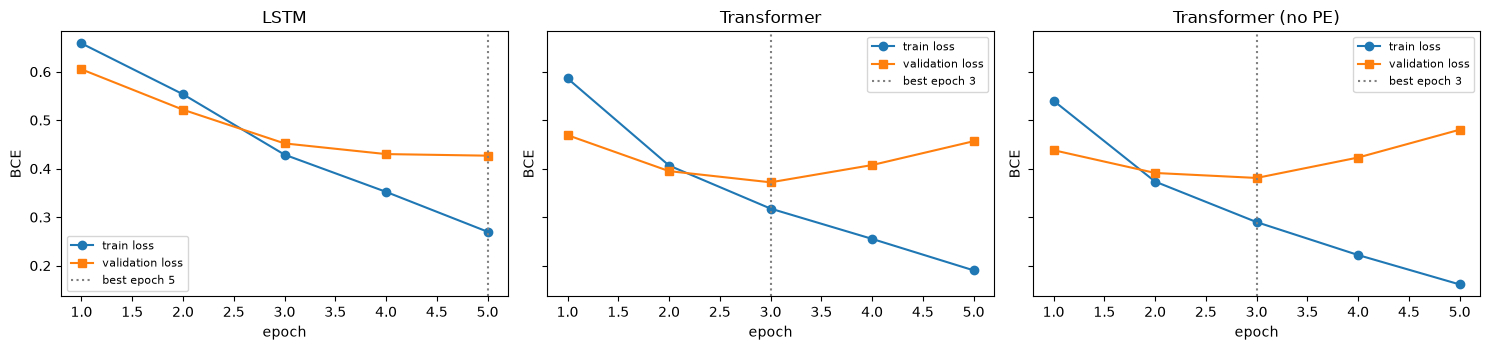

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, r in zip(axes, (r_lstm, r_tf, r_nope)):
    hh = r["hist"]
    ax.plot(hh.epoch, hh.train_loss, "o-", label="train loss")
    ax.plot(hh.epoch, hh.val_loss, "s-", label="validation loss")
    ax.axvline(r["best_epoch"], color="gray", ls=":", label=f"best epoch {r['best_epoch']}")
    ax.set(title=r["name"], xlabel="epoch", ylabel="BCE")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=120)
plt.show()

### Thứ tự từ trên model đã train

Các cặp câu có cùng bag-of-words. Không có PE thì P(pos) phải giống hệt nhau.

In [10]:
def logits_texts(r, texts):
    ids, lens = to_tensors([encode(preprocess(t)) for t in texts], r["L"], r["cls"])
    return predict_logit(r["model"], ids, lens)

sig = lambda z: 1 / (1 + np.exp(-z))
pairs = [("dog bites man", "man bites dog"),
         ("the movie was not bad , it was good", "the movie was not good , it was bad"),
         ("i expected it to be bad but it was great", "i expected it to be great but it was bad"),
         ("great actors , boring story", "boring actors , great story")]
rows = []
for s1, s2 in pairs:
    row = {"S1": s1, "S2": s2}
    for r in (r_lstm, r_tf, r_nope):
        p = sig(logits_texts(r, [s1, s2]))
        row[r["name"]] = f"{p[0]:.3f} / {p[1]:.3f}"
        log("permutation_trained", r["name"], f"{s1} | {s2}", "-", "p_pos_diff", abs(p[0] - p[1]))
    rows.append(row)
# Representation của câu (mean pooling) với model đã train
for r in (r_tf, r_nope):
    m = r["model"]
    with torch.no_grad():
        ids, lens = to_tensors([encode(preprocess(s)) for s in ["dog bites man", "man bites dog"]], 8)
        x = m.emb(ids)
        if m.pe is not None:
            x = m.pe(x)
        H, _ = m.blocks[0](x, torch.arange(8)[None] >= lens[:, None])
        pooled = [(H[i, :lens[i]]).mean(0) for i in range(2)]
    print(f"{r['name']}: ‖pooled(S1) − pooled(S2)‖ = {(pooled[0] - pooled[1]).norm().item():.2e}")
pd.DataFrame(rows)

Transformer: ‖pooled(S1) − pooled(S2)‖ = 7.60e-01
Transformer (no PE): ‖pooled(S1) − pooled(S2)‖ = 9.71e-07


,S1,S2,LSTM,Transformer,Transformer (no PE)
0,dog bites man,man bites dog,0.294 / 0.469,0.059 / 0.041,0.997 / 0.997
1,"the movie was not bad , it was good","the movie was not good , it was bad",0.096 / 0.119,0.022 / 0.072,0.025 / 0.025
2,i expected it to be bad but it was great,i expected it to be great but it was bad,0.689 / 0.347,0.148 / 0.250,0.780 / 0.780
3,"great actors , boring story","boring actors , great story",0.489 / 0.537,0.091 / 0.117,0.775 / 0.775


In [11]:
bins = [0, 64, 128, 256, 10**5]; labels = ["≤64", "65-128", "129-256", ">256"]
bucket = pd.cut(len_test, bins=bins, labels=labels)
acc_len = pd.DataFrame({r["name"]: pd.Series((r["z_test"] > 0) == y_test).groupby(bucket, observed=True).mean()
                        for r in (r_lstm, r_tf, r_nope)})
acc_len.insert(0, "n", pd.Series(bucket).value_counts().reindex(labels).values)
for b, rr in acc_len.iterrows():
    for k, v in rr.items():
        log("exp4_acc_by_length", k, b, "test", "accuracy" if k != "n" else "n", v)
acc_len.round(4)

,n,LSTM,Transformer,Transformer (no PE)
≤64,1352,0.8735,0.8728,0.8683
65-128,5223,0.8650,0.8530,0.8604
129-256,11213,0.8222,0.8311,0.8307
>256,6890,0.7389,0.7476,0.7489


| Model | Params | s/epoch | Best epoch | F1 |
|---|---|---|---|---|
| LSTM | 2,692,609 | 41 | 5 | 0.818 |
| Transformer | 2,692,993 | 122 | 3 | 0.811 |
| Transformer (no PE) | 2,692,993 | 117 | 3 | 0.818 |

- Ba model gần bằng nhau (chênh dưới 1 điểm F1). Transformer **chậm hơn LSTM 3 lần** trên CPU này: tính song song được, nhưng mỗi block có 4 phép chiếu, FFN, LayerNorm và ma trận T × T.
- Transformer học nhanh hơn (tốt nhất ở epoch 3) rồi overfit. LSTM vẫn còn cải thiện ở epoch 5.
- **PE không làm tăng F1 trên IMDb**: sentiment chủ yếu dựa vào từ khoá. Nhưng không có PE thì model không phân biệt thứ tự: các cặp cùng bag-of-words cho P(pos) giống hệt nhau (0.997 / 0.997), và representation của "dog bites man" và "man bites dog" chỉ khác 1e-6. Có PE thì khác (0.76), dù hướng chưa chắc đúng ("expected bad but great" 0.148 so với "expected great but bad" 0.250).
- Khác biệt về performance đến từ: cách tạo representation (h cuối của LSTM so với mean pooling), có hay không có thông tin vị trí, và tốc độ overfit.

## 6. Experiment 2 - Số attention head (d_model = 128 cố định)

In [12]:
head_runs = {4: r_tf}
for hn in [1, 2, 8]:
    head_runs[hn] = run(f"Transformer h={hn}", lambda hn=hn: TransformerClassifier(n_heads=hn),
                        experiment="exp2_heads", setting=f"L=128 h={hn}")
exp2 = pd.DataFrame([{"heads": hn, "d_k": D_MODEL // hn, "params": r["params"], "train_time_s": r["train_time_s"],
                      "accuracy": r["accuracy"], "f1": r["f1"]} for hn, r in sorted(head_runs.items())]).set_index("heads")
exp2.round(4)

  [Transformer h=1] epoch 1: train 0.5952 val 0.4714 val_f1 0.7895 (74 s)


  [Transformer h=1] epoch 2: train 0.4115 val 0.4099 val_f1 0.8074 (88 s)


  [Transformer h=1] epoch 3: train 0.3259 val 0.3946 val_f1 0.8178 (77 s)


  [Transformer h=1] epoch 4: train 0.2596 val 0.4301 val_f1 0.8354 (79 s)


  [Transformer h=1] epoch 5: train 0.2022 val 0.4586 val_f1 0.8233 (77 s)


  [Transformer h=2] epoch 1: train 0.5918 val 0.4750 val_f1 0.7855 (85 s)


... (6 outputs left out)

  [Transformer h=8] epoch 3: train 0.3204 val 0.3905 val_f1 0.8300 (148 s)


  [Transformer h=8] epoch 4: train 0.2479 val 0.4443 val_f1 0.8273 (136 s)


  [Transformer h=8] epoch 5: train 0.1814 val 0.4982 val_f1 0.7974 (137 s)


,d_k,params,train_time_s,accuracy,f1
heads,,,,,
1,128,2692993,395.6073,0.7997,0.7876
2,64,2692993,427.8962,0.8091,0.8023
4,32,2692993,611.8820,0.8147,0.8110
8,16,2692993,711.2896,0.8109,0.8089


- **Số tham số không đổi** (2,692,993) khi tăng head: $W_Q, W_K, W_V, W_O$ vẫn là 128 × 128. Tăng head không tăng representation dimension, chỉ chia nhỏ: $d_k = 128 / h$ = 128, 64, 32, 16.
- F1 tăng từ 0.788 (1 head) lên 0.811 (4 head), rồi không tăng thêm ở 8 head (0.809). Nhiều head có ích, nhưng không phải càng nhiều càng tốt.
- Thời gian tăng theo số head (396 → 711 s) vì phải tính nhiều ma trận T × T nhỏ hơn.

## 7. Experiment 3 - Attention head diversity (model 4 head)

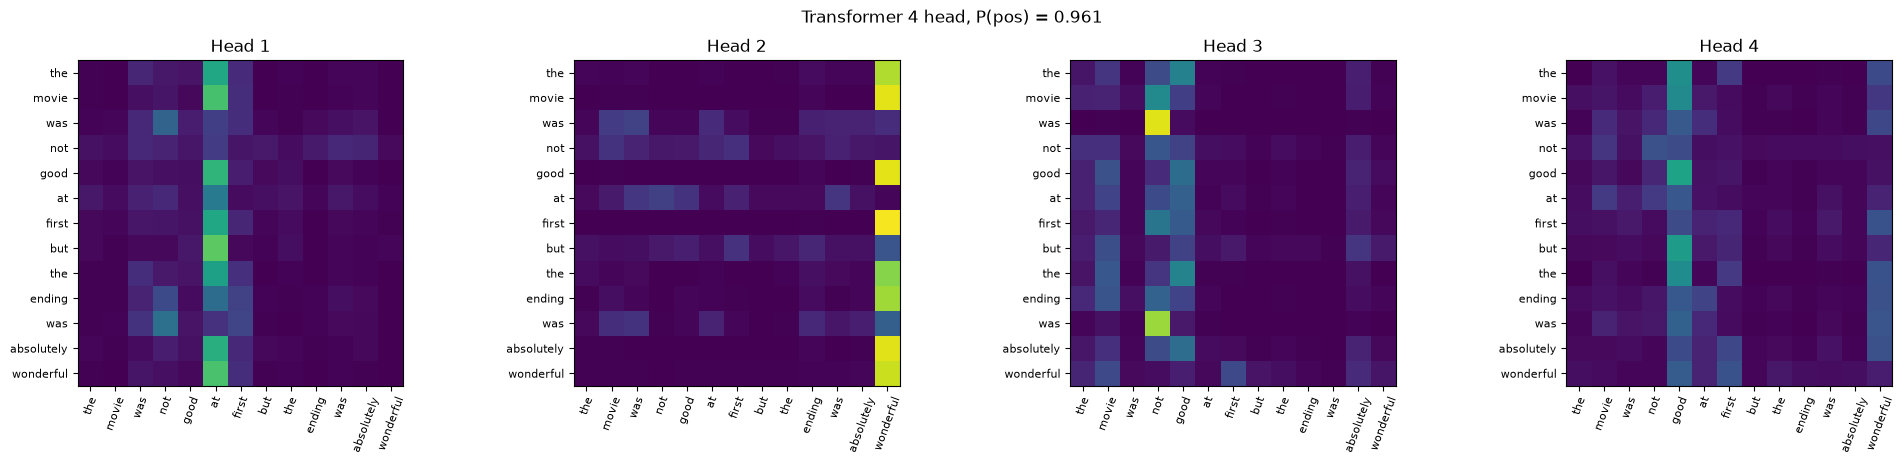

In [13]:
@torch.no_grad()
def attention_of(r, tokens):
    ids, lens = to_tensors([encode(tokens)], len(tokens), r["cls"])
    z, attns = r["model"](ids, lens, return_attn=True)
    return attns[-1][0].numpy(), float(z[0])          # (h, T, T)

demo = preprocess("The movie was not good at first, but the ending was absolutely wonderful.")
A_demo, z_demo = attention_of(r_tf, demo)
fig, axes = plt.subplots(1, N_HEADS, figsize=(5 * N_HEADS, 4.6))
for hd, ax in enumerate(axes):
    ax.imshow(A_demo[hd], cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(len(demo)), demo, rotation=70, fontsize=8)
    ax.set_yticks(range(len(demo)), demo, fontsize=8)
    ax.set_title(f"Head {hd + 1}")
fig.suptitle(f"Transformer 4 head, P(pos) = {sig(z_demo):.3f}")
plt.tight_layout()
plt.savefig("attention_heads.png", dpi=110)
plt.show()

In [14]:
def js(p, q):
    m = (p + q) / 2
    kl = lambda a, b: np.sum(np.where(a > 0, a * np.log(a / b), 0), axis=-1)
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)

rng = np.random.default_rng(SEED)
sample = rng.choice(np.where((len_test >= 20) & (len_test <= MAX_LEN))[0], size=100 if QUICK else 300, replace=False)
ent, mx, jsd = [], [], np.zeros((N_HEADS, N_HEADS))
for i in sample:
    A, _ = attention_of(r_tf, tok_test[i][:MAX_LEN])
    n = A.shape[-1]
    ent.append(-(A * np.log(A + 1e-12)).sum(-1).mean(-1) / np.log(n))
    mx.append(A.max(-1).mean(-1))
    for a in range(N_HEADS):
        for b in range(N_HEADS):
            jsd[a, b] += js(A[a], A[b]).mean() / len(sample)
head_stats = pd.DataFrame({"entropy H/ln n": np.mean(ent, 0), "max weight": np.mean(mx, 0)},
                          index=[f"head {k + 1}" for k in range(N_HEADS)])

# Ablation: tắt từng head, đo F1 trên test
mha = r_tf["model"].blocks[0].attn
Xte_tf, Lte_tf = to_tensors(ids_test, MAX_LEN)
abl = {}
for hd in range(N_HEADS):
    mask = torch.ones(N_HEADS); mask[hd] = 0
    mha.head_mask = mask
    abl[f"head {hd + 1}"] = r_tf["f1"] - f1_score(y_test, (predict_logit(r_tf["model"], Xte_tf, Lte_tf) > 0).astype(int))
mha.head_mask = None
head_stats["ΔF1 khi tắt head"] = pd.Series(abl)
for hname, rr in head_stats.iterrows():
    for k, v in rr.items():
        log("exp3_heads", "Transformer h=4", hname, "test", k, v)
display(head_stats.round(4))
pd.DataFrame(jsd, index=head_stats.index, columns=head_stats.index).round(3).rename_axis("JS divergence")

,entropy H/ln n,max weight,ΔF1 khi tắt head
head 1,0.7657,0.1930,0.0146
head 2,0.7198,0.2392,0.0012
head 3,0.6507,0.2980,0.0043
head 4,0.7480,0.2094,-0.0022


,head 1,head 2,head 3,head 4
JS divergence,,,,
head 1,0.000,0.331,0.345,0.305
head 2,0.331,0.000,0.363,0.326
head 3,0.345,0.363,0.000,0.361
head 4,0.305,0.326,0.361,0.000


- Trên câu ví dụ, mỗi head tập trung vào một token khác nhau: head 2 dồn vào "wonderful", head 4 vào "good", head 3 vào "was"/"not", head 1 vào "at". Hầu hết các hàng trong một head nhìn cùng một cột.
- Trên 300 review: head 3 tập trung nhất (entropy 0.65, max weight 0.30), head 1 phân tán nhất (0.77). JS divergence giữa các cặp head là 0.30 - 0.36, không cặp nào gần 0, tức **các head khác nhau thật**.
- Tắt từng head: head 1 làm F1 giảm 1.5 điểm, head 2 và 3 gần như không ảnh hưởng, tắt head 4 còn làm F1 tăng nhẹ (−0.002). Head 4 gần như redundant.
- Không đặt tên "head ngữ pháp", "head ngữ nghĩa": không có bằng chứng cho điều đó.

## 8. Experiment 5 - Sequence length

Attention memory = batch 64 × 4 head × T² × 4 byte (float32), cho một layer.

In [15]:
len_runs = {MAX_LEN: r_tf}
for L in [32, 64, 256]:
    len_runs[L] = run(f"Transformer L={L}", lambda: TransformerClassifier(), L=L, experiment="exp5_length", setting=f"L={L}")
exp5 = pd.DataFrame([{"L": L, "tokens retained %": 100 * np.minimum(len_test, L).sum() / len_test.sum(),
                      "T²": L * L, "attention memory (MB)": BATCH * N_HEADS * L * L * 4 / 2**20,
                      "s/epoch": r["hist"]["epoch_time_s"].mean(), "train_time_s": r["train_time_s"], "f1": r["f1"]}
                     for L, r in sorted(len_runs.items())]).set_index("L")
for L, rr in exp5.iterrows():
    for k, v in rr.items():
        log("exp5_length", "Transformer", f"L={L}", "test", k, v)
exp5.round(3)

  [Transformer L=32] epoch 1: train 0.6478 val 0.6052 val_f1 0.7188 (21 s)


  [Transformer L=32] epoch 2: train 0.5601 val 0.5658 val_f1 0.7393 (22 s)


  [Transformer L=32] epoch 3: train 0.4860 val 0.5297 val_f1 0.7251 (22 s)


  [Transformer L=32] epoch 4: train 0.4152 val 0.5682 val_f1 0.7080 (22 s)


  [Transformer L=32] epoch 5: train 0.3469 val 0.5974 val_f1 0.7080 (21 s)


  [Transformer L=64] epoch 1: train 0.6197 val 0.5412 val_f1 0.7489 (43 s)


... (6 outputs left out)

  [Transformer L=256] epoch 3: train 0.2624 val 0.3268 val_f1 0.8615 (257 s)


  [Transformer L=256] epoch 4: train 0.2013 val 0.3588 val_f1 0.8615 (319 s)


  [Transformer L=256] epoch 5: train 0.1428 val 0.4280 val_f1 0.8623 (365 s)


,tokens retained %,T²,attention memory (MB),s/epoch,train_time_s,f1
L,,,,,,
32,13.995,1024,1.0,21.423,107.121,0.695
64,27.670,4096,4.0,141.589,707.982,0.760
128,52.054,16384,16.0,122.374,611.882,0.811
256,77.528,65536,64.0,298.632,1493.173,0.841


| L | Token giữ lại | T² | Attention memory | F1 |
|---|---|---|---|---|
| 32 | 14% | 1,024 | 1 MB | 0.695 |
| 64 | 28% | 4,096 | 4 MB | 0.760 |
| 128 | 52% | 16,384 | 16 MB | 0.811 |
| 256 | 78% | 65,536 | 64 MB | 0.841 |

- F1 tăng rõ theo độ dài vì giữ được nhiều nội dung review hơn.
- T gấp đôi thì attention matrix gấp 4. Thời gian một epoch tăng từ 21 s (L = 32) lên 299 s (L = 256), tức gấp 14 lần khi T gấp 8. (Lượt L = 64 có 2 epoch chậm bất thường do máy bận, nên không dùng để so thời gian.)
- Không thể giải quyết mọi thứ bằng cách tăng max_length: chi phí tăng theo bình phương, còn F1 tăng chậm dần.

## 9. Experiment 6 - Pooling: mean vs CLS

CLS-style: thêm token `<cls>` vào đầu câu, dùng output tại vị trí 0 làm representation.

In [16]:
r_cls = run("Transformer CLS", lambda: TransformerClassifier(pooling="cls"), cls=True, experiment="exp6_pooling", setting="L=128 cls")
exp6 = pd.DataFrame([{"pooling": p, "accuracy": r["accuracy"], "f1": r["f1"], "train_time_s": r["train_time_s"],
                      "best_epoch": r["best_epoch"]} for p, r in [("mean", r_tf), ("CLS", r_cls)]]).set_index("pooling")
exp6.round(4)

  [Transformer CLS] epoch 1: train 0.6206 val 0.5558 val_f1 0.7440 (130 s)


  [Transformer CLS] epoch 2: train 0.5169 val 0.4840 val_f1 0.7739 (146 s)


  [Transformer CLS] epoch 3: train 0.4436 val 0.4523 val_f1 0.7919 (148 s)


  [Transformer CLS] epoch 4: train 0.3819 val 0.4134 val_f1 0.8104 (148 s)


  [Transformer CLS] epoch 5: train 0.3261 val 0.4129 val_f1 0.8168 (149 s)


,accuracy,f1,train_time_s,best_epoch
pooling,,,,
mean,0.8147,0.8110,611.8820,3
CLS,0.7982,0.7919,720.7078,5


- Mean pooling (F1 0.811) tốt hơn CLS (0.792) sau 5 epoch. CLS học chậm hơn (vẫn đang cải thiện ở epoch 5) vì một token phải tự học cách gom thông tin của cả câu, còn mean pooling dùng sẵn mọi token.
- Cách lấy sequence representation có ảnh hưởng tới kết quả. Với model nhỏ, train từ đầu, mean pooling là lựa chọn an toàn hơn.

## 10. Evaluation

,params,train_time_s,accuracy,precision,recall,f1
name,,,,,,
LSTM,2692609,204.1529,0.8108,0.7940,0.8423,0.8175
Transformer,2692993,611.8820,0.8147,0.8326,0.7904,0.8110
Transformer (no PE),2692993,585.5817,0.8162,0.8167,0.8182,0.8175
Transformer CLS,2692993,720.7078,0.7982,0.8227,0.7634,0.7919


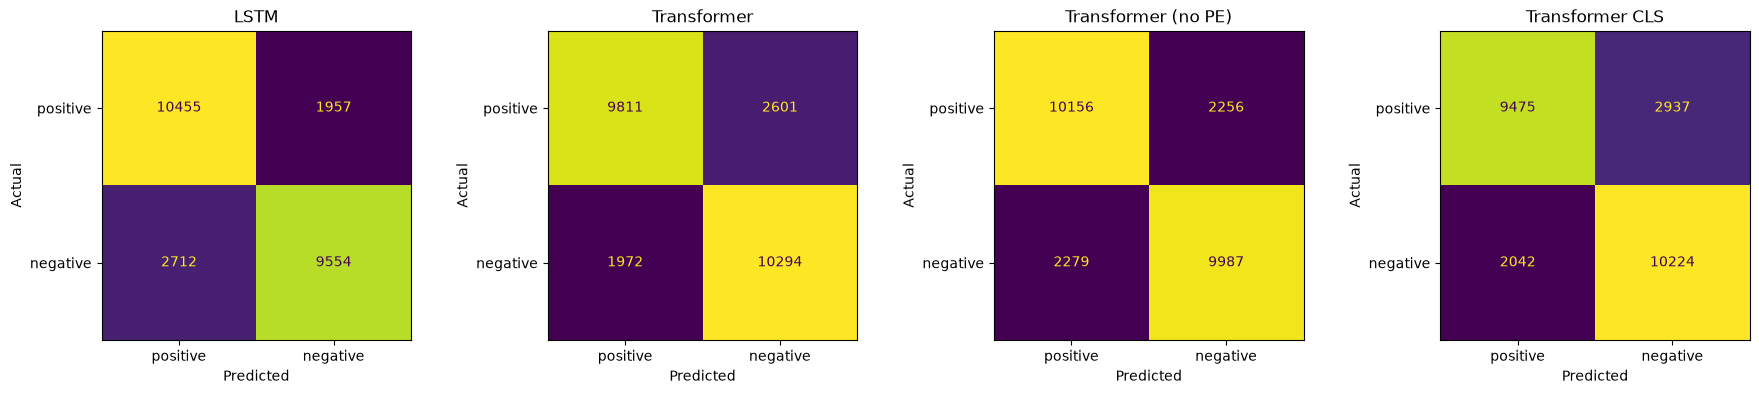

In [17]:
final_runs = [r_lstm, r_tf, r_nope, r_cls]
final = pd.DataFrame([{k: r[k] for k in ["name", "params", "train_time_s", "accuracy", "precision", "recall", "f1"]}
                      for r in final_runs]).set_index("name")
for n, rr in final.iterrows():
    for k in ["accuracy", "precision", "recall", "f1"]:
        log("evaluation", n, "final", "test", k, rr[k])
display(final.round(4))
fig, axes = plt.subplots(1, len(final_runs), figsize=(4.5 * len(final_runs), 4))
for ax, r in zip(axes, final_runs):
    cm = confusion_matrix(y_test, (r["z_test"] > 0).astype(int), labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["positive", "negative"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set(title=r["name"], xlabel="Predicted", ylabel="Actual")
    for k, v in zip(["TP", "FN", "FP", "TN"], cm.ravel()):
        log("evaluation", r["name"], "confusion_matrix", "test", k, v)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=120)
plt.show()

## 11. Application

Raw text → tokenizer → token IDs → embedding → PE → Transformer → mean pooling → Linear. Với mỗi câu: prediction, P(pos), attention nhận được của từng token (trung bình trên head và hàng) và occlusion Δz = z(câu) − z(câu bỏ token).

In [18]:
def occlusion(r, toks):
    ids = encode(toks)
    variants = [ids] + [ids[:i] + ids[i + 1:] for i in range(len(ids))]
    X, lens = to_tensors(variants, r["L"], r["cls"])
    z = predict_logit(r["model"], X, lens)
    return z[0], z[0] - z[1:]

def explain(r, text):
    toks = preprocess(text)[: r["L"]]
    A, z = attention_of(r, toks)
    received = A.mean(0).mean(0)                    # attention mỗi token nhận được
    _, dz = occlusion(r, toks)
    return toks, z, received, dz

APP = {"ngắn": "I really enjoyed this movie.",
       "dài": ("The film opens slowly in a small coastal town, and for almost an hour the director shows the daily "
               "routines of the village. Some viewers will find this slow. Then the second half changes everything: "
               "the performances become intense, the photography is stunning, and the last twenty minutes are among "
               "the most moving I have seen in years. Highly recommended."),
       "negation": "I did not like this movie at all.",
       "contrast": "I thought this movie would be bad, but it was actually excellent.",
       "ambiguous": "The movie was okay, not great but not terrible either."}
app_rows = []
for kind, text in APP.items():
    toks, z, rec, dz = explain(r_tf, text)
    row = {"loại": kind, "prediction": "Positive" if z > 0 else "Negative", "P(pos) Transformer": sig(z)}
    for r in (r_nope, r_lstm):
        row[f"P(pos) {r['name']}"] = float(sig(logits_texts(r, [text])[0]))
    row["top attention"] = ", ".join(f"{toks[i]} {rec[i]:.2f}" for i in np.argsort(-rec)[:3])
    row["top |Δz|"] = ", ".join(f"{toks[i]} {dz[i]:+.2f}" for i in np.argsort(-np.abs(dz))[:3])
    app_rows.append(row)
    log("application", "Transformer", kind, "-", "p_pos", sig(z))
pd.DataFrame(app_rows).set_index("loại").round(3)

,prediction,P(pos) Transformer,P(pos) Transformer (no PE),P(pos) LSTM,top attention,top |Δz|
loại,,,,,,
ngắn,Positive,0.963,0.941,0.758,"really 0.30, enjoyed 0.21, i 0.21","enjoyed +3.89, really +2.31, this +0.70"
dài,Positive,0.642,0.742,0.987,"opens 0.17, twenty 0.06, coastal 0.05","twenty -1.08, minutes -0.94, opens -0.71"
negation,Negative,0.003,0.035,0.306,"not 0.20, did 0.18, all 0.16","did -0.80, not -0.41, all +0.34"
contrast,Negative,0.129,0.309,0.534,"bad 0.21, thought 0.12, excellent 0.12","bad -4.83, excellent +2.78, would -1.60"
ambiguous,Negative,0.004,0.003,0.152,"okay 0.30, terrible 0.16, not 0.11","terrible -2.30, great +0.82, the +0.64"


- **Ngắn** "I really enjoyed this movie." → Positive 0.963. Đúng, dựa vào enjoyed (+3.89).
- **Dài** → Positive 0.642. Đúng, nhưng kém tự tin hơn LSTM (0.987).
- **Negation** "I did not like this movie at all." → Negative 0.003. Đúng.
- **Contrast** "I thought this movie would be bad, but it was actually excellent." → Negative 0.129. **Sai**: bad (−4.83) mạnh hơn excellent (+2.78). LSTM đúng (0.534).
- **Ambiguous** "The movie was okay, not great but not terrible either." → Negative 0.004. Khó nói đúng hay sai, nhưng model quá tự tin. "terrible" (−2.30) quyết định dù đang bị phủ định.

Attention nhận được cao nhất thường là từ cảm xúc (really, enjoyed, bad, okay) nhưng không luôn trùng với occlusion. Ví dụ câu dài: attention cao nhất ở "opens".

## 12. Error analysis

In [19]:
ea = test_df.assign(n_tokens=len_test, z=r_tf["z_test"], z_lstm=r_lstm["z_test"])
ea["pred"] = (ea.z > 0).astype(int); ea["correct"] = ea.pred == ea.label; ea["conf"] = ea.z.abs()
print(f"Tỉ lệ lỗi: {100 * (~ea.correct).mean():.1f}% | bị truncate (> {MAX_LEN} token): "
      f"{100 * (~ea.correct[ea.n_tokens > MAX_LEN]).mean():.1f}% | không truncate: {100 * (~ea.correct[ea.n_tokens <= MAX_LEN]).mean():.1f}%")
short = ea[ea.n_tokens.between(15, 100)]
cases = pd.concat([short[short.correct].nlargest(3, "conf"), short[~short.correct & (short.label == 0)].nlargest(3, "conf"),
                   short[~short.correct & (short.label == 1)].nlargest(3, "conf")])
for i, rr in cases.iterrows():
    toks, z, rec, dz = explain(r_tf, rr.text)
    print(f"#{i} true={LABEL_NAMES[rr.label]} pred={LABEL_NAMES[rr.pred]} P(pos)={sig(z):.3f} LSTM={sig(rr.z_lstm):.3f}\n"
          f"   {rr.text[:300]}\n   attention: {', '.join(f'{toks[j]} {rec[j]:.2f}' for j in np.argsort(-rec)[:5])}\n"
          f"   occlusion: {', '.join(f'{toks[j]} {dz[j]:+.2f}' for j in np.argsort(-np.abs(dz))[:5])}")

Tỉ lệ lỗi: 18.5% | bị truncate (> 128 token): 20.1% | không truncate: 14.3%
#14127 true=positive pred=positive P(pos)=0.999 LSTM=0.987
   A delightful and wonderful film, which has entered my pantheon of great romantic comedies. IN many ways it's even better than "When Harry met Sally." IT wears well on viewing and re-viewing. The cast is excellent, and both David Duchovny and Minnie Driver give us really believable characters.
   attention: wonderful 0.14, delightful 0.05, excellent 0.04, wears 0.04, david 0.04
   occlusion: wonderful +0.13, delightful +0.11, better -0.03, even -0.03, both +0.02
#17967 true=positive pred=positive P(pos)=0.999 LSTM=0.984
   A wonderful film - a charming, quirky family story. A cross-country journey filled with lots of interesting, oddball stops along the way (& several very cool cameos). Great cast led by Rod Steiger carries the film along and leads to a surprise ending. Well directed & shot - a really nice movie.
   attention: wonderful 0.16, family 0

#6412 true=negative pred=positive P(pos)=0.997 LSTM=0.987
   Masterpiece. Carrot Top blows the screen away. Never has one movie captured the essence of the human spirit quite like "Chairman of the Board." 10/10... don't miss this instant classic.
   attention: carrot 0.12, masterpiece 0.09, 10 0.09, human 0.08, 10 0.07
   occlusion: masterpiece +1.34, captured +0.48, screen +0.40, top +0.35, human +0.28
#11134 true=negative pred=positive P(pos)=0.997 LSTM=0.899
   Nice movie and Nicholle Tom does a fantastic job playing the "guy in the girl's body", she really does it well.<br /><br />A sort of teen version of many other movies, but well done.<br /><br />Well casted, from "Matt" to "Matt2".
   attention: fantastic 0.09, does 0.06, well 0.05, sort 0.05, matt 0.05
   occlusion: fantastic +1.11, matt +0.42, job +0.37, sort -0.33, other +0.31
#17840 true=positive pred=negative P(pos)=0.006 LSTM=0.013
   If you're looking for a not-so-serious mob movie, with a female as the lead, you're in 

#12735 true=positive pred=negative P(pos)=0.018 LSTM=0.042
   David Morse and Andre Braugher are very talented actors, which is why I'm trying so hard to support this program. Unfortunately, an irrational plot, and very poor writing is making it difficult for me. I'm hoping that the show gets a serious overhaul, or that the actors find new projects that are wo
   attention: unfortunately 0.11, david 0.10, morse 0.08, poor 0.07, andre 0.06
   occlusion: morse -0.59, unfortunately -0.47, andre +0.47, poor -0.45, show +0.41


In [20]:
# Attention nhận được có trùng với token quan trọng theo occlusion không? (200 review)
rho, top1 = [], []
for i in sample[:100 if QUICK else 200]:
    toks, z, rec, dz = explain(r_tf, " ".join(tok_test[i]))
    rho.append(spearmanr(rec, np.abs(dz)).statistic)
    top1.append(int(np.argmax(rec) == np.argmax(np.abs(dz))))
faith = {"spearman(attention, |Δz|)": float(np.nanmean(rho)), "top-1 trùng": float(np.mean(top1))}
for k, v in faith.items():
    log("faithfulness", "Transformer", "200 reviews", "test", k, v)
faith

{'spearman(attention, |Δz|)': 0.2742446787417989, 'top-1 trùng': 0.485}

- Tỉ lệ lỗi 18.5%: 20.1% trên review bị truncate, 14.3% trên review không bị truncate.
- Attention và occlusion tương quan vừa phải (Spearman 0.27). Token có attention cao nhất trùng với token quan trọng nhất trong 48.5% review. Attention cho thấy phân phối trọng số, không phải lời giải thích.
- Chi tiết ở `error_analysis.md`.

## 13. Lưu kết quả

In [21]:
if not QUICK:
    pd.DataFrame(RESULTS).to_csv("results.csv", index=False)
print(len(RESULTS), "dòng" + ("" if QUICK else " đã ghi vào results.csv"))

404 dòng đã ghi vào results.csv
